In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd
import numpy as np

# Replace with a unique value for your team (e.g., roll number)
np.random.seed(1234)

n_matches = 200
dates = pd.date_range("2024-01-01", periods=n_matches)
branches = ["CSE", "ECE", "Mechanical", "Civil", "EEE"]

rows = []
for date in dates:
    is_toss_won = np.random.rand() < 0.5
    is_home_ground = np.random.rand() < 0.5
    is_final = np.random.rand() < 0.05
    team_fitness_index = np.random.normal(75, 10)
    opposition_bowling_rating = max(0, np.random.normal(70, 12))

    branch = np.random.choice(branches)
    base = {"CSE": 145, "ECE": 138, "Mechanical": 130, "Civil": 125, "EEE": 135}[branch]

    runs = base
    runs += 12 if is_toss_won else -5
    runs += 15 if is_home_ground else 0
    runs += 20 if is_final else 0
    runs += (team_fitness_index - 75) * 0.8
    runs -= (opposition_bowling_rating - 70) * 0.9
    runs += np.random.normal(0, 10)
    runs = max(0, round(runs))

    rows.append([date, branch, is_toss_won, is_home_ground, is_final,
                 round(team_fitness_index, 1), round(opposition_bowling_rating, 1), runs])

df = pd.DataFrame(rows, columns=["date", "branch", "is_toss_won", "is_home_ground", "is_final",
                                   "team_fitness_index", "opposition_bowling_rating", "runs_scored"])

# Introduces missing values and invalid entries to simulate real-world data quality issues
mask = np.random.rand(len(df)) < 0.03
df.loc[mask, "team_fitness_index"] = np.nan
df.loc[df.sample(frac=0.02).index, "runs_scored"] = df["runs_scored"] * -1

df.to_csv("cricket_league_data.csv", index=False)
print(df.shape)
df.head()

(200, 8)


,date,branch,is_toss_won,is_home_ground,is_final,team_fitness_index,opposition_bowling_rating,runs_scored
0,2024-01-01,ECE,True,False,False,81.6,78.1,157
1,2024-01-02,ECE,False,False,False,NaN,94.0,106
2,2024-01-03,Mechanical,False,True,False,71.1,69.4,146
3,2024-01-04,Civil,False,False,False,66.2,58.2,102
4,2024-01-05,ECE,False,True,False,73.2,82.7,136


In [ ]:
df=pd.read_csv("/content/cricket_league_data.csv")

In [ ]:
df

,date,branch,is_toss_won,is_home_ground,is_final,team_fitness_index,opposition_bowling_rating,runs_scored
0,2024-01-01,ECE,True,False,False,81.6,78.1,157
1,2024-01-02,ECE,False,False,False,NaN,94.0,106
2,2024-01-03,Mechanical,False,True,False,71.1,69.4,146
3,2024-01-04,Civil,False,False,False,66.2,58.2,102
4,2024-01-05,ECE,False,True,False,73.2,82.7,136
...,...,...,...,...,...,...,...,...
195,2024-07-14,EEE,False,False,False,87.8,82.8,118
196,2024-07-15,ECE,False,False,False,85.0,79.3,136
197,2024-07-16,EEE,False,False,False,78.2,75.3,124
198,2024-07-17,CSE,False,False,False,69.8,55.5,157


In [ ]:
df.shape

(200, 8)

In [ ]:
df.dtypes

,0
date,object
branch,object
is_toss_won,bool
is_home_ground,bool
is_final,bool
team_fitness_index,float64
opposition_bowling_rating,float64
runs_scored,int64


In [ ]:
df.columns

Index(['date', 'branch', 'is_toss_won', 'is_home_ground', 'is_final',
       'team_fitness_index', 'opposition_bowling_rating', 'runs_scored'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
date,0
branch,0
is_toss_won,0
is_home_ground,0
is_final,0
team_fitness_index,7
opposition_bowling_rating,0
runs_scored,0


In [ ]:
df.head()

,date,branch,is_toss_won,is_home_ground,is_final,team_fitness_index,opposition_bowling_rating,runs_scored
0,2024-01-01,ECE,True,False,False,81.6,78.1,157
1,2024-01-02,ECE,False,False,False,NaN,94.0,106
2,2024-01-03,Mechanical,False,True,False,71.1,69.4,146
3,2024-01-04,Civil,False,False,False,66.2,58.2,102
4,2024-01-05,ECE,False,True,False,73.2,82.7,136


In [ ]:
df["date"]=pd.to_datetime(df["date"])


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
missing_before = df['team_fitness_index'].isnull().sum()
print(f"Missing fitness values: {missing_before}")

Missing fitness values: 7


In [ ]:
median_fitness = df['team_fitness_index'].median()
df['team_fitness_index'] = df['team_fitness_index'].fillna(median_fitness)

In [ ]:
negative_count = (df['runs_scored'] < 0).sum()
print(f"Negative runs : {negative_count}")
if negative_count > 0:
    df['runs_scored'] = df['runs_scored'].abs()

Negative runs : 4


In [ ]:
df.shape

(200, 8)

In [ ]:
print(f"Runs range: {df['runs_scored'].min()} to {df['runs_scored'].max()}")

Runs range: 92 to 199


Text(0, 0.5, 'Average Runs')

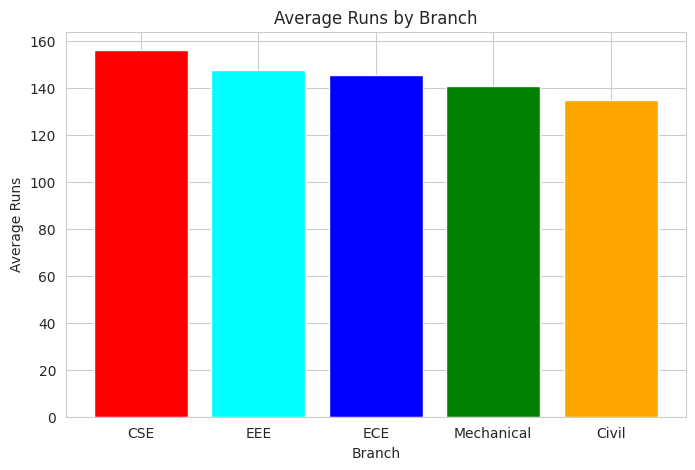

In [ ]:
branch_avg = df.groupby('branch')['runs_scored'].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(branch_avg.index, branch_avg.values, color=['red', 'cyan', 'blue', 'green', 'orange'])
plt.title('Average Runs by Branch')
plt.xlabel('Branch')
plt.ylabel('Average Runs')

Text(0, 0.5, 'Average Runs')

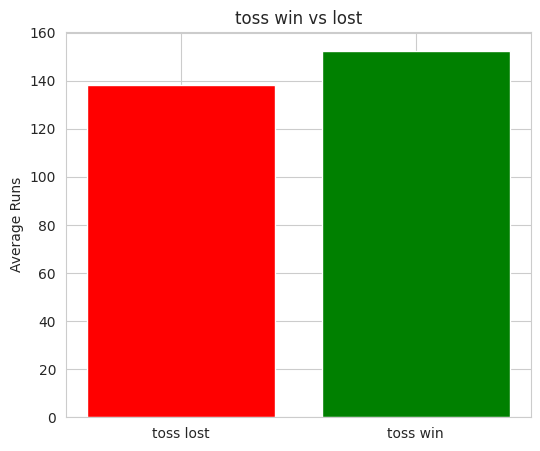

In [ ]:
toss_avg=df.groupby("is_toss_won")['runs_scored'].mean()
plt.figure(figsize=(6, 5))
plt.bar(["toss lost","toss win"],toss_avg.values,color=['red', 'green'])
plt.title('toss win vs lost')
plt.ylabel('Average Runs')

Text(0, 0.5, 'Average Runs')

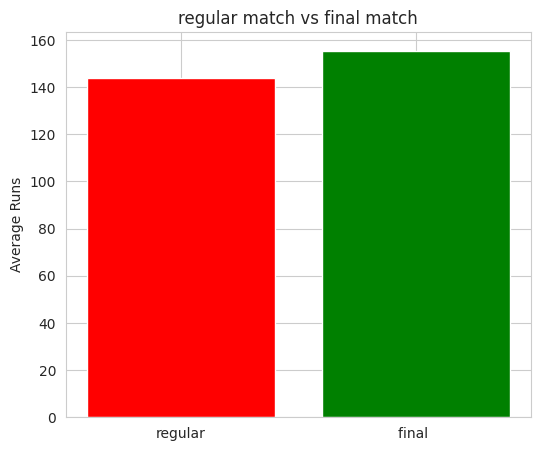

In [ ]:
final_avg=df.groupby("is_final")['runs_scored'].mean()
plt.figure(figsize=(6, 5))
plt.bar(["regular" , "final "],final_avg.values,color=['red', 'green'])
plt.title('regular match vs final match')
plt.ylabel('Average Runs')

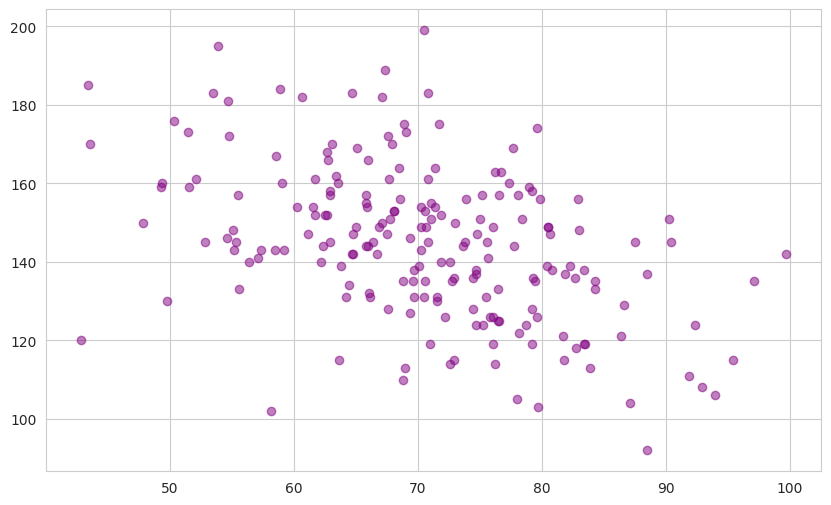

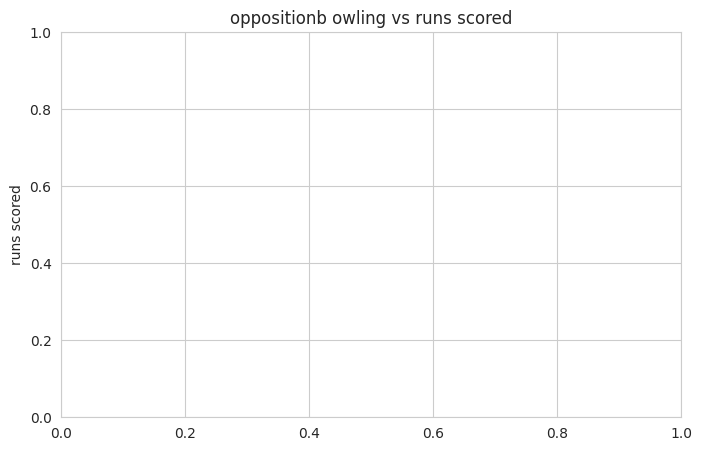

In [ ]:
plt.scatter(df["opposition_bowling_rating"],df["runs_scored"],alpha=0.5,color="purple")
plt.figure(figsize=(8, 5))
plt.title('oppositionb owling vs runs scored')
plt.ylabel('runs scored')
plt.show()

In [ ]:
df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month

In [ ]:
df = df.sort_values(['branch', 'date']).reset_index(drop=True)

In [ ]:
df['rolling_avg_runs'] = df.groupby('branch')['runs_scored'].transform(
    lambda x: x.shift(1).expanding().mean()
)

In [ ]:
branch_means = df.groupby('branch')['runs_scored'].transform('mean')
df['rolling_avg_runs'] = df['rolling_avg_runs'].fillna(branch_means)

In [ ]:
print(f"\n total columns : {list(df.columns)}")


 total columns : ['date', 'branch', 'is_toss_won', 'is_home_ground', 'is_final', 'team_fitness_index', 'opposition_bowling_rating', 'runs_scored', 'day_of_week', 'month', 'rolling_avg_runs']


PREPROCESSING

In [ ]:
df_encoded = pd.get_dummies(df, columns=['branch'], drop_first=True)
print([col for col in df_encoded.columns if 'branch_' in col])

['branch_Civil', 'branch_ECE', 'branch_EEE', 'branch_Mechanical']


In [ ]:
feature_columns = ['is_toss_won', 'is_home_ground', 'is_final','team_fitness_index', 'opposition_bowling_rating','day_of_week', 'month', 'rolling_avg_runs'] +[col for col in df_encoded.columns if 'branch_' in col]

In [ ]:
X = df_encoded[feature_columns]
y = df_encoded['runs_scored']

In [ ]:
print(f"{len(feature_columns)}")

12


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\ntrain {len(X_train)} ")
print(f"test {len(X_test)} ")



train 160 
test 40 


In [ ]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor()
    }

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)


    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)


    print(list(models.keys())[i])

    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')

    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))

    print('='*35)
    print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 9.2543
- Mean Absolute Error: 7.3483
- R2 Score: 0.7686
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 9.4050
- Mean Absolute Error: 7.1270
- R2 Score: 0.7909


Decision Tree
Model performance for Training set
- Root Mean Squared Error: 0.0000
- Mean Absolute Error: 0.0000
- R2 Score: 1.0000
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 19.5634
- Mean Absolute Error: 16.2750
- R2 Score: 0.0951


Random Forest Regressor
Model performance for Training set
- Root Mean Squared Error: 5.2363
- Mean Absolute Error: 4.1191
- R2 Score: 0.9259
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 13.7918
- Mean Absolute Error: 11.3005
- R2 Score: 0.5503




In [ ]:
rf_params = {"max_depth": [5, 8, 15, None, 10],
             "max_features": [5, 7, "auto", 8],
             "min_samples_split": [2, 8, 15, 20],
             "n_estimators": [100, 200, 500, 1000]}

In [ ]:
randomcv_models = [("RF", RandomForestRegressor(), rf_params) ]

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

model_param = {}
for name, model, params in randomcv_models:
    random = RandomizedSearchCV(estimator=model,
                                   param_distributions=params,
                                   n_iter=100,
                                   cv=3,
                                   verbose=2,
                                   n_jobs=-1)
    random.fit(X_train, y_train)
    model_param[name] = random.best_params_

for model_name in model_param:
    print(f"---------------- Best Params for {model_name} -------------------")
    print(model_param[model_name])

Fitting 3 folds for each of 100 candidates, totalling 300 fits
---------------- Best Params for RF -------------------
{'n_estimators': 200, 'min_samples_split': 2, 'max_features': 8, 'max_depth': 15}


In [ ]:
models = {
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, min_samples_split=2, max_features=5, max_depth=None,
                                                     n_jobs=-1)}
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])

    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')

    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))

    print('='*35)
    print('\n')

Random Forest Regressor
Model performance for Training set
- Root Mean Squared Error: 5.0508
- Mean Absolute Error: 3.9417
- R2 Score: 0.9311
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 14.1308
- Mean Absolute Error: 11.4966
- R2 Score: 0.5279




 New match data


In [ ]:
new_match = pd.DataFrame({
    'is_toss_won': [True],
    'is_home_ground': [True],
    'is_final': [False],
    'team_fitness_index': [82],
    'opposition_bowling_rating': [68],
    'day_of_week': [5],
    'month': [8],
    'rolling_avg_runs': [150],
    'branch_Civil': [0],
    'branch_ECE': [0],
    'branch_EEE': [0],
    'branch_Mechanical': [0]
})
new_match = new_match[X_train.columns]
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
predicted_runs_lr = lr_model.predict(new_match)
print("Predicted Runs:", round(predicted_runs_lr[0], 2))

Predicted Runs: 183.79
